# GymWorkoutRecognition&RepsCountingWithIMU+HBC-AI

**Author**: Fabio Colombo (fabio.colombo04@universitadipavia.it) - ID 580655.

**Motivations**: Wearable sensors have been widely explored in the past
decades for lifestyle characterization and health monitoring,
and a large part of them have been evaluated particularly for
detecting human body motion. The inertial sensor (IMU) is undoubtedly the most popular modality as it is widely integrated into
everyday smart devices, benefiting from low cost and power
consumption. However, the inertial sensor is designed to sense
the motion pattern of the object where it is attached. To avoid this problem, the paper evaluates the effective contribution of a potential wearable motion sensing modality that is still not fully explored but shows impressive potential in wearable HAR (Human Activity Recognition): the passive body-area electrostatic field, also indicated as human body capacitance (HBC).

**References**: This work is an attempt to replicate the results presented in the paper "[Hybrid CNN-Dilated Self-attention Model Using Inertial and Body-Area Electrostatic Sensing for Gym Workout Recognition, Counting, and User Authentification](https://arxiv.org/abs/2503.06311)". The "[RecGym](https://www.kaggle.com/datasets/zhaxidelebsz/10-gym-exercises-with-615-abstracted-features/data)" dataset was used to train, validate, and test all the models; further information is listed below.

**Disclaimer**: This project for the final exam of the Deep Learning course is intended for research purposes only. Some of the considerations contained in this notebook are part of the original paper.

## Methodology

### Dataset
The RecGym dataset comprises 10 subjects performing 11 gym exercises (plus a
"Null"/idle class), recorded simultaneously with a wrist/leg/pocket-worn IMU
(6-axis: 3-axis accelerometer + 3-axis gyroscope) and a body-area capacitive
(HBC) sensor, sampled at 20 Hz. Each subject performed the full exercise set
on 5 separate days, with 3 repetitions of machine/free-weight exercises and 1
repetition of aerobic/cardio exercises per session.

<img src="https://drive.google.com/uc?export=view&id=1hj9CIHTaozjyQXt3Ipc6BnRj3rvJO8yP" width="400" height="400">

### Preprocessing: sliding-window segmentation
Each subject's continuous recording is split into fixed-length windows
following the paper's protocol (Sec. IV-A): 4-second windows (80 samples at
20 Hz) with 2-second (50%) overlap between consecutive windows. Each window
is assigned a single label via majority vote over its samples, since exercise
transitions can fall inside a window's boundaries. Windows are built
independently per subject, so no window ever mixes data from two different
people -- this is essential both for temporal consistency and for the
Leave-One-Subject-Out (LOSO) evaluation described below.

<img src="https://drive.google.com/uc?export=view&id=1ojlxyTV_XN-00-4l_73WqjJ9peLmLyQk" width="500" height="300">

### Model architecture
The classifier follows the "Hybrid CNN-Dilated Self-Attention" architecture
proposed in the paper (Fig. 5): each window is processed by a CNN
feature-extraction block (temporal convolution + channel mixing + a second
temporal convolution), followed by a multi-head self-attention block and a
dilated causal convolution block, applied over 4 overlapping sub-windows
whose class predictions are finally averaged. For the combined IMU+HBC
configuration, the two signal sources are processed by two independent CNN
branches before being concatenated ("post-CNN fusion"), which the paper
reports as marginally more effective than fusing the raw signals at the input.

<img src="https://drive.google.com/uc?export=view&id=1EQwuWKO_KrgaChmQbwe3NyNsrvwBZF6J" width="450" height="400">

The network has three main blocks: a **CNN block** for spatial/temporal feature extraction, a **multi-head self-attention block**, and a **dilated convolution block** for capturing longer-range dependencies.

The **CNN block** applies three convolutional layers:

- 2D conv with 32 kernels of size (1, SamplingRate/2) extracting per-channel frequency features
- depthwise conv with kernel (channel, 1) and 2 filters per channel extracting spatial features
- conv with 128 filters of size (1, 10) refining temporal features
Each layer is followed by layer normalization and ELU activation; average pooling (1, 2) and dropout (0.1) are applied after the second and third layers.

The CNN output is split into four overlapping windows, each processed by a **four-head self-attention block** using dot-product attention to weight time steps.

Each attended window then passes through a **two-layer dilated convolution** (32 filters, kernel size 3, dilation rate 2), producing the final representation used by a dense + softmax classifier.

<img src="https://drive.google.com/uc?export=view&id=1fMfvdhcb82xFkcK_lHQKhM9YF4j3PEBa" width="375" height="250">

Training uses categorical cross-entropy loss, Adam optimizer, learning rate 0.0001, with a 0.5 decay rate every 200 steps.

### Evaluation protocol
Models are evaluated with **Leave-One-Subject-Out (LOSO) cross-validation**:
for each subject, the model is trained from scratch on the remaining
subjects and tested on the held-out one, for each of the three sensor
positions (wrist, leg, pocket) and three signal-source configurations
(HBC-only, IMU-only, combined).

**Implemented pipeline:**
1. Loading the **RecGym** dataset (IMU + capacitive/HBC sensor)
2. Column normalization, class-label setup, and an optional **`FAST_MODE`** toggle to speed up training by reducing subjects/classes/grid size (Sections 1.1-1.3)
3. Preprocessing and windowing (4s windows, 2s overlap by default, 20Hz → 80 samples/window)
4. Hybrid **CNN + Multi-Head Self-Attention + Dilated Convolution** architecture (the "Post-Fusion" scheme from Fig. 5 of the paper)
5. Training with **Leave-One-Subject-Out (LOSO) cross-validation**, for the three signal sources (HBC, IMU, combined) and the three sensor positions (wrist, leg, pocket)
6. Evaluation: accuracy, macro F1, confusion matrix
7. **Repetition counting** via FFT smoothing + peak detection (Acc, Gyro, HBC)
8. Final results summary using ROC/PR curves


## 0. Environment setup

In [1]:
!pip install -q scikit-learn peakutils pandas numpy matplotlib

In [2]:

# --- Standard library imports -----------------------------------------------
import os
import copy

# --- Numerical / data handling imports --------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- PyTorch imports ----------------------------------------------------------
import torch
import torch.nn as nn
import torch.nn.functional as F

# --- scikit-learn utilities ---------------------------------------------------
from sklearn.utils import shuffle
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# --- SciPy: used for majority-vote labeling of each window -------------------
from scipy.stats import mode as scipy_mode

# --- Peak detection library used for repetition counting ---------------------
import peakutils

# --- Added for this revision: DataLoader-based batching, progress bars,
# LR scheduler, and richer evaluation metrics -----------------------------
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR
from tqdm.auto import tqdm
from sklearn.metrics import (classification_report, precision_score, recall_score,
                              roc_curve, auc, precision_recall_curve)
from sklearn.preprocessing import label_binarize

# --- used to remove a warning due to different version of PyTorch
import warnings
warnings.filterwarnings("ignore", message=".*torch.cuda.amp.GradScaler.*", category=FutureWarning)

# Fix random seeds everywhere for reproducibility of shuffling / weight init
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Select GPU if available, otherwise fall back to CPU.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU name:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu128
Device: cuda
GPU name: Tesla T4


## GOOGLE MOUNT

In [3]:
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/Deep_Learning_Project/data'
os.makedirs(SAVE_DIR, exist_ok=True)
print(f"Results will be saved to / loaded from: {SAVE_DIR}")


Mounted at /content/drive
Results will be saved to / loaded from: /content/drive/MyDrive/Deep_Learning_Project/data


In [4]:
import pickle, json

# --- Reload dataset and metadata -------------------------------------------
df = pd.read_parquet(os.path.join(SAVE_DIR, "df_processed.parquet"))
with open(os.path.join(SAVE_DIR, "metadata.json"), "r") as f:
    metadata = json.load(f)
classes_labels = metadata["classes_labels"]
label_map = metadata["label_map"]
N_CLASSES = metadata["N_CLASSES"]
feature_cols_full = metadata["feature_cols_full"]

# --- Reload LOSO results (metrics, predictions, probabilities) -------------
with open(os.path.join(SAVE_DIR, "all_results.pkl"), "rb") as f:
    all_results = pickle.load(f)

# --- Reload counting tables, if previously saved ----------------------------
counting_path = os.path.join(SAVE_DIR, "counting_df.csv")
if os.path.exists(counting_path):
    counting_df = pd.read_csv(counting_path)

diag_path = os.path.join(SAVE_DIR, "diag_df.csv")
if os.path.exists(diag_path):
    diag_df = pd.read_csv(diag_path)


def load_model(position, sensor_mode, device=None):
    # Rebuilds a HybridCNNDilatedAttention model and loads its saved weights
    # for a given (position, sensor_mode) combination. Requires build_model
    # (Section 3) to already be defined in this session.
    device = device or DEVICE
    checkpoint = torch.load(os.path.join(SAVE_DIR, f"hbc_model_{position}_{sensor_mode}.pth"),
                             map_location=device)
    model = build_model(sensor_mode=checkpoint["sensor_mode"],
                         n_classes=checkpoint["n_classes"]).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    return model


# Also reconstruct positions/sensor_modes from the reloaded results, so that
# Section 6/7 cells (which iterate over `positions`) work without rerunning
# Section 5.
positions = sorted({key.rsplit("_", 1)[0] for key in all_results.keys()})
sensor_modes = sorted({key.rsplit("_", 1)[1] for key in all_results.keys()})

print(f"Reloaded {len(df)} rows, {len(all_results)} result entries.")
print(f"Positions: {positions}  Sensor modes: {sensor_modes}")
print("Example: model = load_model('wrist', 'combine')")


Reloaded 907869 rows, 9 result entries.
Positions: ['leg', 'pocket', 'wrist']  Sensor modes: ['cap', 'combine', 'imu']
Example: model = load_model('wrist', 'combine')



## 1 . Loading the RecGym dataset


In [ ]:
# --- Automatic download from Kaggle ---

!pip install -q kaggle
# Download and unzip the RecGym dataset directly into ./data
!kaggle datasets download -d zhaxidelebsz/10-gym-exercises-with-615-abstracted-features -p ./data --unzip
# Pick the first CSV file found in ./data as the dataset path
DATA_PATH = [os.path.join("./data", f) for f in os.listdir("./data") if f.lower().endswith(".csv")][0]
print("Dataset found at:", DATA_PATH)

Dataset URL: https://www.kaggle.com/datasets/zhaxidelebsz/10-gym-exercises-with-615-abstracted-features
License(s): MIT
100% 111M/111M [00:03<00:00, 35.9MB/s]

Dataset found at: ./data/RecGym.csv


In [ ]:

# Load the raw CSV exactly as downloaded/uploaded, before any renaming or cleaning
df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
print("\nAvailable columns:", df_raw.columns.tolist())
df_raw.head()


Shape: (4703320, 11)

Available columns: ['Subject', 'Position', 'Session', 'A_x', 'A_y', 'A_z', 'G_x', 'G_y', 'G_z', 'C_1', 'Workout']


,Subject,Position,Session,A_x,A_y,A_z,G_x,G_y,G_z,C_1,Workout
0,1,wrist,1,0.501125,0.500625,0.500500,0.500156,0.499962,0.500313,0.501227,Null
1,1,wrist,1,0.500250,0.499750,0.501250,0.499531,0.500550,0.500081,0.501584,Null
2,1,wrist,1,0.500250,0.499375,0.501875,0.499613,0.500231,0.500119,0.501508,Null
3,1,wrist,1,0.499625,0.499750,0.500875,0.499494,0.500350,0.500588,0.502032,Null
4,1,wrist,1,0.500000,0.499000,0.501000,0.499650,0.500588,0.499769,0.501756,Null



### 1.1 Column name normalization

The exact column schema may vary slightly depending on the CSV version. This cell detects the columns for **subject**, **session/day**, **sensor position**, and **exercise
label**, renaming them to a standard schema.


In [ ]:

# List of possible variants that might appear in different releases of the dataset.
candidate_col_map = {
    "Subject":  ["Subject", "Object", "User", "subject", "object", "user_id"],
    "Session":  ["Session", "Day", "session", "day"],
    "Position": ["Sensor_Position", "Position", "position", "sensor_position"],
    "Workout":  ["Workout", "workout", "Label", "label", "activity"],
}

def find_col(df, candidates):
    # Return the first candidate column name that actually exists in df,
    # or None if none of them are present.
    for c in candidates:
        if c in df.columns:
            return c
    return None

# Build a rename mapping {original_name: standard_name} by searching for each
# standard column among its known candidate spellings.
rename_dict = {}
for std_name, candidates in candidate_col_map.items():
    found = find_col(df_raw, candidates)
    if found is None:
        # Warn loudly if a required column could not be located automatically,
        # so the user can inspect df_raw.columns and fix the mapping manually.
        print(f"[WARNING] No column found for '{std_name}'. "
              f"Candidates tried: {candidates}. Check df_raw.columns manually and update the mapping.")
    else:
        rename_dict[found] = std_name
        print(f"'{found}' -> '{std_name}'")

# Apply the renaming so the rest of the notebook can rely on consistent column names
df = df_raw.rename(columns=rename_dict).copy() # final clean data frame

# These are the raw sensor channels used throughout the notebook:
# For IMU sensor: A_x/A_y/A_z = 3-axis accelerometer, G_x/G_y/G_z = 3-axis gyroscope,
# C_1 = HBC (body capacitance) channel.
feature_cols_full = ["A_x", "A_y", "A_z", "G_x", "G_y", "G_z", "C_1"]
missing_feats = [c for c in feature_cols_full if c not in df.columns]
assert not missing_feats, f"Missing feature columns: {missing_feats} -- check the names in the original CSV."

# Drop any row missing a feature value or a label, since it cannot be used for
# either training or windowing.
df = df.dropna(subset=feature_cols_full + ["Workout"]).reset_index(drop=True)
print("\nShape after cleaning:", df.shape)
print("\nClass distribution:\n", df["Workout"].value_counts())
print("\nSensor positions found:", df["Position"].unique() if "Position" in df.columns else "N/A")


'Subject' -> 'Subject'
'Session' -> 'Session'
'Position' -> 'Position'
'Workout' -> 'Workout'

Shape after cleaning: (4703320, 11)

Class distribution:
 Workout
Null            2607111
Walking          283040
StairClimber     280012
Riding           263124
Squat            251788
Running          215231
LegPress         165790
ArmCurl          159626
Adductor         145107
BenchPress       141630
LegCurl          137735
RopeSkipping      53126
Name: count, dtype: int64

Sensor positions found: ['wrist' 'leg' 'pocket']



### 1.2 Class label setup

Defines the 12 target classes (11 gym exercises + `Null`), normalizes a few
naming variants that may appear in different CSV releases, and maps each
class name to an integer id.


In [ ]:

# The 12 target classes: 11 gym exercises plus the "Null" class (idle/rest periods)
classes_labels = ["Adductor", "ArmCurl", "BenchPress", "LegCurl", "LegPress", "Null",
                   "Riding", "RopeSkipping", "Running", "Squat", "StairClimber", "Walking"]

# A few naming variants are normalized here,
# in case the CSV uses slightly different spelling/spacing for exercise names.
label_aliases = {
    "Stairsclimber": "StairClimber",
    "Stairs Climber": "StairClimber",
    "Stair Climber": "StairClimber",
    "StairsClimber": "StairClimber",
    "Arm Curl": "ArmCurl",
    "Bench Press": "BenchPress",
    "Leg Curl": "LegCurl",
    "Leg Press": "LegPress",
    "Rope Skipping": "RopeSkipping",
}
df["Workout"] = df["Workout"].replace(label_aliases)

# Sanity check: flag any label that is still not part of our known class list,
# so it can be added to classes_labels/label_aliases instead of silently dropped.
unknown_labels = set(df["Workout"].unique()) - set(classes_labels)
if unknown_labels:
    print(f"[WARNING] Unrecognized labels: {unknown_labels}. "
          f"Add them to 'classes_labels' or 'label_aliases' if needed.")

# Map each class name to an integer id (used directly as the target for PyTorch's CrossEntropyLoss)
label_map = {name: i for i, name in enumerate(classes_labels)}
df["Workout_id"] = df["Workout"].map(label_map)

print("Classes:", classes_labels)
print("\nClass distribution:\n", df["Workout"].value_counts())


Classes: ['Adductor', 'ArmCurl', 'BenchPress', 'LegCurl', 'LegPress', 'Null', 'Riding', 'RopeSkipping', 'Running', 'Squat', 'StairClimber', 'Walking']

Class distribution:
 Workout
Null            2607111
Walking          283040
StairClimber     280012
Riding           263124
Squat            251788
Running          215231
LegPress         165790
ArmCurl          159626
Adductor         145107
BenchPress       141630
LegCurl          137735
RopeSkipping      53126
Name: count, dtype: int64



### 1.3 FAST_MODE -- speed up training (optional)

Training the full grid (3 positions x 3 sensor modes x up to 10 LOSO folds
each) can take a long time even with CUDA. This cell provides a single `FAST_MODE` switch that applies several speed-up levers at once:

1. **Fewer subjects** -- keep only `N_SUBJECTS_FAST` randomly chosen subjects
   instead of all of them, so each LOSO grid has fewer folds to train.
2. **Fewer classes** -- optionally drop some workout classes entirely
   (`CLASSES_TO_DROP`), shrinking both the row count and the classification
   problem size. `Null` is always kept, since it is needed as the "no
   exercise" background class.
3. **Downsampled `Null` class** -- the `Null` class is by far the most
   frequent one (idle/rest periods) and inflates the dataset without adding
   much information; `NULL_KEEP_FRACTION` controls what fraction of it to
   keep.
4. **Fewer (position, sensor_mode) combinations** -- restrict `positions`
   and `sensor_modes` to a subset instead of the full 3x3 grid (this is
   applied later, in Section 5).
5. **Mixed precision** -- enables float16 autocast + gradient scaling on
   compatible GPUs, which can meaningfully speed up
   training with negligible accuracy impact. In PyTorch this is handled via
   `torch.autocast` + `torch.cuda.amp.GradScaler` in the training loop
   (Section 4), controlled by the `USE_MIXED_PRECISION` flag set here.

Set `FAST_MODE = False` to disable all of this and run the full pipeline as
described in the paper (all subjects, all classes, all positions, all sensor
modes).


In [ ]:

FAST_MODE = True  # set to False to run the full pipeline

# --- Lever 1: keep only a subset of subjects (fewer LOSO folds) -------------
N_SUBJECTS_FAST = 5
RANDOM_SEED_SUBJECTS = 42

# --- Lever 2: drop some workout classes entirely ----------------------------
CLASSES_TO_DROP = ["Riding", "Running", "StairClimber", "Walking"]

# --- Lever 3: downsample the dominant "Null" class --------------------------
NULL_KEEP_FRACTION = 0.3

# --- Lever 5: mixed precision floating point (GPU speed-up) -----------------
USE_MIXED_PRECISION = True


if FAST_MODE:
    print("FAST_MODE is ON -- applying dataset reduction levers.\n")

    # --- Lever 1: subject subsampling ---------------------------------------
    rng = np.random.default_rng(RANDOM_SEED_SUBJECTS)
    all_subjects = df["Subject"].unique()
    n_keep = min(N_SUBJECTS_FAST, len(all_subjects))
    sampled_subjects = rng.choice(all_subjects, size=n_keep, replace=False)
    df = df[df["Subject"].isin(sampled_subjects)].reset_index(drop=True)
    print(f"[Lever 1] Kept {n_keep} of {len(all_subjects)} subjects: {sorted(sampled_subjects)}") # kept rows from df related to the sampled subjects

    # --- Lever 2: class dropping ---------------------------------------------
    if CLASSES_TO_DROP:
        before = len(df)
        df = df[~df["Workout"].isin(CLASSES_TO_DROP)].reset_index(drop=True)
        print(f"[Lever 2] Dropped classes {CLASSES_TO_DROP}: "
              f"{before} -> {len(df)} rows")

        # Rebuild classes_labels/label_map to match the reduced set, keeping
        # the original relative ordering of the remaining classes.
        classes_labels = [c for c in classes_labels if c not in CLASSES_TO_DROP]
        label_map = {name: i for i, name in enumerate(classes_labels)}
        df["Workout_id"] = df["Workout"].map(label_map)
        print(f"[Lever 2] Remaining classes ({len(classes_labels)}): {classes_labels}")

    # --- Lever 3: downsample "Null" -------------------------------------------
    if NULL_KEEP_FRACTION < 1.0 and "Null" in df["Workout"].unique():
        null_mask = df["Workout"] == "Null"
        null_rows = df[null_mask]
        other_rows = df[~null_mask]
        null_sampled = null_rows.sample(frac=NULL_KEEP_FRACTION, random_state=RANDOM_SEED_SUBJECTS) # frac: what percentage of rows to keep

        # Re-sort by subject (and session, if available) to preserve the
        # temporal order required by make_windows() -- random sampling
        # shuffles row order otherwise.
        sort_cols = ["Subject", "Session"] if "Session" in df.columns else ["Subject"]
        df = (pd.concat([other_rows, null_sampled])
                .sort_values(sort_cols) # sorted by sort_cols
                .reset_index(drop=True)) # index resetted otherwise not sequential indexing
        print(f"[Lever 3] Downsampled 'Null' to {NULL_KEEP_FRACTION:.0%} "
              f"({len(null_sampled)} of {len(null_rows)} rows kept)")

    print("\nClass distribution after FAST_MODE reduction:\n", df["Workout"].value_counts())
    print("\nTotal rows after FAST_MODE reduction:", len(df))

    if USE_MIXED_PRECISION and DEVICE.type != "cuda":
        print("\n[Lever 5] Mixed precision requested but no CUDA GPU detected -- "
              "it will have no effect on CPU. Training will run in full precision.")

else:
    print("FAST_MODE is OFF -- running the full pipeline (all subjects, all classes).")
    USE_MIXED_PRECISION = False

# This is used later in Section 4/5 so the model's output layer and the
# integer label range always match however many classes remain after any
# of the levers above.
N_CLASSES = len(classes_labels)
print("\nFinal number of classes used for training:", N_CLASSES)


FAST_MODE is ON -- applying dataset reduction levers.

[Lever 1] Kept 4 of 10 subjects: [np.int64(1), np.int64(5), np.int64(6), np.int64(7)]
[Lever 2] Dropped classes ['Riding', 'Running', 'StairClimber', 'Walking']: 1871440 -> 1467523 rows
[Lever 2] Remaining classes (8): ['Adductor', 'ArmCurl', 'BenchPress', 'LegCurl', 'LegPress', 'Null', 'RopeSkipping', 'Squat']
[Lever 3] Downsampled 'Null' to 30% (316653 of 1055511 rows kept)

Class distribution after FAST_MODE reduction:
 Workout
Null            316653
Squat           104218
LegPress         64646
ArmCurl          58211
LegCurl          56841
Adductor         55754
BenchPress       51275
RopeSkipping     21067
Name: count, dtype: int64

Total rows after FAST_MODE reduction: 728665

Final number of classes used for training: 8



## 2 . Preprocessing and windowing

Following the paper (Sec. IV-A): sliding window of **4 seconds** (80 samples at
20Hz), **2-second** overlap (40 samples), one label per window assigned by
**majority vote** over the samples it contains. Windowing is performed
separately for each subject (to avoid mixing boundaries across different
subjects).


In [ ]:
# Sliding window parameters, following the paper (Sec. IV-A):
# 4-second windows, 20 Hz sampling rate -> 80 samples per window,
# 2-second overlap -> 40-sample stride between consecutive windows.
WINDOW_SIZE = 80
STRIDE = 40

def make_windows(df_pos):
    # Segments a DataFrame (already filtered for a single sensor position)
    # into sliding windows, one subject at a time, so a window never mixes
    # data from two different people.
    X_list = []
    y_list = []
    subj_list = []

    for subj in df_pos["Subject"].unique(): # loop for each subject in order to garantee that each window comes from a single subject's temporal session.
        df_subj = df_pos[df_pos["Subject"] == subj].reset_index(drop=True)
        sensor_data = df_subj[feature_cols_full].values
        labels = df_subj["Workout_id"].values

        for start in range(0, len(df_subj) - WINDOW_SIZE, STRIDE):
            end = start + WINDOW_SIZE
            window = sensor_data[start:end]                                   # window containing the info about the subject's exercise
            window_labels = labels[start:end]

            # MAJORITY VOTE: the window gets the label that appears most
            # often among its 80 samples.
            values, counts = np.unique(window_labels, return_counts=True)     # VALUES contains labels of different exercises in the window; COUNTS containts num. of labels of each exercise inside the window
            window_label = values[np.argmax(counts)]

            X_list.append(window)
            y_list.append(window_label)
            subj_list.append(subj)

    X = np.array(X_list)             # shape: (N, 80, 7) --> (num. windows, timesteps, channels)
    y = np.array(y_list)             # shape: (N,) --> one label per window
    subj_arr = np.array(subj_list)   # shape: (N,) --> one subject per window
    return X, y, subj_arr


## 3 . Architecture: Hybrid CNN-Dilated Self-Attention (PyTorch)

Follows the same conceptual stages as Fig. 5 of the paper: a CNN block,
followed by a multi-head self-attention block and a dilated convolution
block, applied over `n_windows` internal sliding windows whose outputs are
then averaged ("sliding-window ensembling").

**Design note (PyTorch vs. the original Keras code)**: Input kept in
the natural PyTorch convention for time series, `(batch, channels, time)`,
and channel-mixing is done with a plain `1x1 Conv1d` (a per-time-step dense
projection across channels).

In [ ]:

class PermuteLayerNorm(nn.Module):
    # PyTorch's nn.LayerNorm normalizes over the LAST dimension(s) of its
    # input, but our tensors are in (batch, channels, time) format (channels
    # second, as is standard for nn.Conv1d). This small wrapper transposes to
    # (batch, time, channels), applies LayerNorm over the channel dimension,
    # then transposes back -- reproducing the effect of Keras'
    # LayerNormalization() (which normalizes over the last/channel axis in
    # the channels-last convention used by the original code).
    def __init__(self, num_channels):
        super().__init__()
        self.ln = nn.LayerNorm(num_channels)

    def forward(self, x):
        # x: (batch, channels, time)
        x = x.transpose(1, 2)     # -> (batch, time, channels)
        x = self.ln(x)
        x = x.transpose(1, 2)     # -> (batch, channels, time)
        return x


class ConvBlock(nn.Module):
    # CNN feature-extraction block (see Fig. 5 of the paper):
    #   Conv1d -> LayerNorm -> ELU
    #   -> 1x1 Conv1d (channel mixing, analogous to the original DepthwiseConv2D) -> LayerNorm -> ELU -> Dropout
    #   -> Conv1d -> LayerNorm -> ELU -> Dropout
    def __init__(self, in_channels, F1=32, D=4, kernel_size=20, dropout=0.1):
        super().__init__()
        F2 = F1 * D

        self.conv1 = nn.Conv1d(in_channels, F1, kernel_size=kernel_size, padding="same")
        self.ln1 = PermuteLayerNorm(F1)

        # 1x1 conv across channels, expanding F1 -> F1*D: plays the same role
        # as the original DepthwiseConv2D (per-time-step channel mixing),
        # implemented here as a straightforward pointwise convolution.
        self.channel_mix = nn.Conv1d(F1, F2, kernel_size=1)
        self.ln2 = PermuteLayerNorm(F2)
        self.dropout1 = nn.Dropout(dropout)

        self.conv2 = nn.Conv1d(F2, F2, kernel_size=10, padding="same")
        self.ln3 = PermuteLayerNorm(F2)
        self.dropout2 = nn.Dropout(dropout)

        self.out_channels = F2

    def forward(self, x):
        # x: (batch, in_channels, time)
        x = F.elu(self.ln1(self.conv1(x)))
        x = self.dropout1(F.elu(self.ln2(self.channel_mix(x))))
        x = self.dropout2(F.elu(self.ln3(self.conv2(x))))
        return x  # (batch, F2, time)

#-------------------------------------------------------------------------------

class AttentionBlock(nn.Module):
    # Multi-head self-attention block with a residual (skip) connection.
    # LayerNorm first, then self-attention
    # then dropout, then add the original input back.
    def __init__(self, embed_dim, num_heads=4, dropout=0.1):
        super().__init__()
        self.ln = nn.LayerNorm(embed_dim)
        self.mha = nn.MultiheadAttention(embed_dim, num_heads=num_heads,
                                          dropout=dropout, batch_first=True)
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        # x: (batch, time, embed_dim)  -- note: channels-LAST here, since
        # nn.MultiheadAttention with batch_first=True expects (batch, seq, embed)
        x_norm = self.ln(x)
        attn_out, _ = self.mha(x_norm, x_norm, x_norm, need_weights=False) # attention weights dropped
        return x + self.dropout(attn_out)  # residual connection

#-------------------------------------------------------------------------------

class CausalDilatedConv1d(nn.Module):
    # A Conv1d with left-only ("causal") padding, so that output[t] only
    # depends on input[<= t] -- matching Keras' padding="causal" used in the
    # original dilated_conv_block. Padding amount = (kernel_size - 1) * dilation
    # ensures the output sequence length equals the input sequence length.
    def __init__(self, in_channels, out_channels, kernel_size, dilation):
        super().__init__()
        self.pad_amount = (kernel_size - 1) * dilation # zeros added to keep same input-output lenght
        self.conv = nn.Conv1d(in_channels, out_channels, kernel_size=kernel_size,
                               dilation=dilation, padding=0) # padding handle later on

    def forward(self, x):
        # x: (batch, channels, time) -- pad only on the left (past) side to make convolution CAUSAL
        x = F.pad(x, (self.pad_amount, 0))
        return self.conv(x)


class DilatedConvBlock(nn.Module):
    # Residual dilated convolution block (2 layers, shared dilation rate), as
    # described in the paper: "two-layer dilated convolution ... dilation
    # rate of two".
    def __init__(self, in_channels, filters=32, kernel_size=3, dilation_rate=2, dropout=0.1):
        super().__init__()
        self.conv1 = CausalDilatedConv1d(in_channels, filters, kernel_size, dilation_rate)
        self.bn1 = nn.BatchNorm1d(filters)
        self.dropout1 = nn.Dropout(dropout)

        self.conv2 = CausalDilatedConv1d(filters, filters, kernel_size, dilation_rate)
        self.bn2 = nn.BatchNorm1d(filters)
        self.dropout2 = nn.Dropout(dropout)

        # Residual/skip connection: if the channel dimension changed, project
        # the input with a 1x1 conv so it can be added to the block's output.
        if in_channels != filters:
            self.shortcut = nn.Conv1d(in_channels, filters, kernel_size=1)
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        # x: (batch, channels, time)
        residual = self.shortcut(x)
        out = self.dropout1(F.elu(self.bn1(self.conv1(x))))
        out = self.dropout2(F.elu(self.bn2(self.conv2(out))))
        return F.elu(out + residual)

#-------------------------COMPLETE NETWORK--------------------------------------

class HybridCNNDilatedAttention(nn.Module):
    # Full model: CNN block(s) -> n_windows x [attention -> dilated conv] -> average logits.
    # sensor_mode: 'cap' (HBC only, 1 channel), 'imu' (IMU only, 6 channels),
    # 'combine' (IMU+HBC, 7 channels, post-CNN fusion via two separate branches).
    def __init__(self, sensor_mode="combine", n_classes=12, n_windows=4,
                 F1=32, D=4, kernel_size=20, dropout=0.1,
                 di_filters=32, di_kernel_size=3, di_dropout=0.1,
                 num_heads=4, attn_dropout=0.1):
        super().__init__()
        self.sensor_mode = sensor_mode
        self.n_windows = n_windows

        if sensor_mode == "combine":
            # Two separate CNN branches: one for the 6 IMU channels, one for
            # the single HBC channel, concatenated afterward ("post-CNN" fusion).
            self.imu_branch = ConvBlock(6, F1=F1, D=D, kernel_size=kernel_size, dropout=dropout)
            self.cap_branch = ConvBlock(1, F1=F1, D=D, kernel_size=kernel_size, dropout=dropout)
            fused_channels = self.imu_branch.out_channels + self.cap_branch.out_channels
        elif sensor_mode == "imu":
            self.single_branch = ConvBlock(6, F1=F1, D=D, kernel_size=kernel_size, dropout=dropout)
            fused_channels = self.single_branch.out_channels
        elif sensor_mode == "cap":
            self.single_branch = ConvBlock(1, F1=F1, D=D, kernel_size=kernel_size, dropout=dropout)
            fused_channels = self.single_branch.out_channels
        else:
            raise ValueError("sensor_mode must be 'cap', 'imu', or 'combine'")

        self.attention_blocks = nn.ModuleList([
            AttentionBlock(fused_channels, num_heads=num_heads, dropout=attn_dropout)
            for _ in range(n_windows)
        ])
        self.dilated_blocks = nn.ModuleList([
            DilatedConvBlock(fused_channels, filters=di_filters, kernel_size=di_kernel_size,
                              dilation_rate=2, dropout=di_dropout)
            for _ in range(n_windows)
        ])
        self.classifiers = nn.ModuleList([
            nn.Linear(di_filters, n_classes) for _ in range(n_windows)
        ])

    def forward(self, x):
        # x: (batch, channels, time) where channels = 1 (cap), 6 (imu), or 7 (combine)
        if self.sensor_mode == "combine":
            imu_x = x[:, 0:6, :] # (batch, channels, 80)
            cap_x = x[:, 6:7, :]
            block = torch.cat([self.imu_branch(imu_x), self.cap_branch(cap_x)], dim=1)
        else:
            block = self.single_branch(x)

        # block: (batch, fused_channels, time) -> transpose once to
        # (batch, time, fused_channels) for the attention sub-blocks
        block_t = block.transpose(1, 2)
        total_time = block_t.shape[1]

        # Sliding-window ensembling: apply attention + dilated conv on
        # n_windows overlapping sub-sequences, then average their logits.
        logits_list = []
        for w in range(self.n_windows):
            st = w
            end = total_time - self.n_windows + w + 1
            seg = block_t[:, st:end, :]                      # (batch, sub_time, fused_channels)
            seg = self.attention_blocks[w](seg)                # self-attention over this sub-window

            seg_cf = seg.transpose(1, 2)                       # back to (batch, channels, sub_time) for conv
            seg_cf = self.dilated_blocks[w](seg_cf)             # (batch, di_filters, sub_time)
            seg_last = seg_cf[:, :, -1]                        # representation of the last time step

            logits_list.append(self.classifiers[w](seg_last))  # (batch, n_classes)

        # Average the per-window logits (equivalent to Average() + softmax in
        # the Keras version -- softmax itself is handled by CrossEntropyLoss
        # during training, and by an explicit F.softmax at inference time).
        logits = torch.stack(logits_list, dim=0).mean(dim=0) # logits_list: tensors for each sub-window
        return logits


def build_model(sensor_mode="combine", n_classes=12, n_windows=4):
    return HybridCNNDilatedAttention(sensor_mode=sensor_mode, n_classes=n_classes, n_windows=n_windows)


# Quick sanity check of the shapes: builds the model once, runs a dummy batch
# through it, and prints the parameter count and output shape (does not train
# anything, just verifies the architecture is wired correctly).
_test_model = build_model(sensor_mode="combine", n_classes=N_CLASSES).to(DEVICE)
_dummy_input = torch.randn(4, 7, 80).to(DEVICE)   # (batch=4, channels=7, time=80)
_dummy_output = _test_model(_dummy_input)
n_params = sum(p.numel() for p in _test_model.parameters() if p.requires_grad) # it counts all trainable parameters
print(f"Output shape: {tuple(_dummy_output.shape)}  (expected: (4, {N_CLASSES}))")
print(f"Trainable parameters: {n_params:,}")
del _test_model, _dummy_input, _dummy_output


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/conv.py:370: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /pytorch/aten/src/ATen/native/Convolution.cpp:1024.)
  return F.conv1d(


Output shape: (4, 8)  (expected: (4, 8))
Trainable parameters: 1,542,112



## 4 . Training -- Leave-One-Subject-Out cross-validation (Training loop)

As in the paper, the model is evaluated with **LOSO**: for each subject, the
model is trained on the other 9 (or fewer, under FAST_MODE) and tested on the
held-out one. Class imbalance (far more "Null" samples than any other class)
is handled with `nn.CrossEntropyLoss(weight=...)`, using a per-class weight
inversely proportional to class frequency.

We track the best validation accuracy
seen so far, save a copy of the model's weights whenever it improves, and
stop once `patience` epochs have passed without improvement.

**Note on training time**: the paper uses up to 1000 epochs with
`patience=100`. For faster iteration the default here is much smaller
(`epochs=150`, `patience=20`, or the even smaller FAST_MODE values set in
Section 5).


In [ ]:

def compute_class_weight_tensor(y_train, n_classes, device):
    # Inverse-frequency class weighting: rarer classes get a higher weight so
    # the loss does not get dominated by the very frequent "Null" class.
    # Returns a tensor of shape (n_classes,) suitable for
    # nn.CrossEntropyLoss(weight=...).
    classes, counts = np.unique(y_train, return_counts=True)
    total = counts.sum()
    weights = np.ones(n_classes, dtype=np.float32)  # default weight for any class absent in this fold
    for c, cnt in zip(classes, counts):
        weights[c] = total / (len(classes) * cnt) # different weights based on the rarity of the class
    return torch.tensor(weights, dtype=torch.float32, device=device)


def make_dataloader(X, y, batch_size, shuffle_data=True):
    # Wraps numpy arrays into a TensorDataset + DataLoader
    X_t = torch.from_numpy(X).float() # numpy array --> Pytorch tensor
    y_t = torch.from_numpy(y).long()
    dataset = TensorDataset(X_t, y_t) # it packs multiple tensors together in order to create a dataset
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle_data,
                       pin_memory=torch.cuda.is_available())


def run_epoch(model, dataloader, criterion, device, phase="train", optimizer=None, scaler=None):
    # Single-epoch loop shared by both training and validation
    is_train = (phase == "train")
    model.train() if is_train else model.eval()

    total_loss, correct, n_seen = 0.0, 0, 0
    all_preds, all_probs = [], [] # final predictions and probabilities accumulated

    pbar = tqdm(dataloader, desc=phase, leave=False)
    for xb, yb in pbar:
        xb = xb.to(device)
        yb = yb.to(device)

        if is_train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(is_train): # dynamic torch.no_grad()
            if scaler is not None and is_train: # scaler needed just during training
                with torch.autocast(device_type="cuda", dtype=torch.float16):
                    logits = model(xb)
                    loss = criterion(logits, yb)
            else:
                logits = model(xb)
                loss = criterion(logits, yb)

        if is_train:
            if scaler is not None:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            else:
                loss.backward()
                optimizer.step()

        preds = logits.argmax(dim=1)
        probs = F.softmax(logits.detach(), dim=-1) # it converts the logits in true probabilities through softmax

        total_loss += loss.item() * len(xb)
        correct += (preds == yb).sum().item()
        n_seen += len(xb)
        all_preds.append(preds.detach().cpu().numpy())
        all_probs.append(probs.cpu().numpy())

        pbar.set_postfix({"loss": f"{loss.item():.4f}"})

    return (total_loss / n_seen, correct / n_seen,
            np.concatenate(all_preds), np.concatenate(all_probs))


def run_loso(X, y, subjects, sensor_mode, n_classes=12, n_windows=4,
             epochs=150, batch_size=256, lr=1e-4, patience=20, device=None,
             use_mixed_precision=False, use_scheduler=False, verbose=False):
    device = device or DEVICE
    unique_subjects = np.unique(subjects)
    per_subject_acc, per_subject_f1 = [], []
    all_y_true, all_y_pred, all_y_proba = [], [], []

    # Tracks the single best-performing fold's weights across the whole LOSO
    # run, so a representative trained model can be persisted to disk
    # afterward without having to save every single fold.
    overall_best_acc = -1.0
    overall_best_state = None

    # --- Leave-One-Subject-Out loop: iterate once per subject -------------
    for test_subj in unique_subjects:
        # Boolean masks
        train_mask = subjects != test_subj
        test_mask = subjects == test_subj

        X_train, y_train = X[train_mask], y[train_mask]
        X_test, y_test = X[test_mask], y[test_mask]

        if len(X_test) == 0 or len(X_train) == 0:
            print(f"[{sensor_mode}] Subject {test_subj}: insufficient data, skipping.")
            continue

        # Shuffle only the training set
        X_train, y_train = shuffle(X_train, y_train, random_state=SEED)

        # Reshape windows from (N, time, channels) to the PyTorch Conv1d
        # convention (N, channels, time) -- the transpose of the last two axes.
        X_train_r = np.transpose(X_train, (0, 2, 1)).astype(np.float32)
        X_test_r = np.transpose(X_test, (0, 2, 1)).astype(np.float32)

        train_loader = make_dataloader(X_train_r, y_train, batch_size, shuffle_data=True)
        test_loader = make_dataloader(X_test_r, y_test, batch_size, shuffle_data=False)

        # Build a fresh model for this fold
        model = build_model(sensor_mode=sensor_mode, n_classes=n_classes, n_windows=n_windows).to(device)

        class_weights = compute_class_weight_tensor(y_train, n_classes, device)
        criterion = nn.CrossEntropyLoss(weight=class_weights)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
        # Optional cosine-annealing LR schedule (off by default: opt in via use_scheduler=True)
        scheduler = CosineAnnealingLR(optimizer, T_max=epochs) if use_scheduler else None

        scaler = torch.cuda.amp.GradScaler() if (use_mixed_precision and device.type == "cuda") else None

        best_val_acc = -1.0
        best_state = None
        epochs_without_improvement = 0

        for epoch in range(epochs):
            train_loss, train_acc, _, _ = run_epoch(
                model, train_loader, criterion, device, phase="train",
                optimizer=optimizer, scaler=scaler)
            val_loss, val_acc, _, _ = run_epoch(
                model, test_loader, criterion, device, phase="val")

            if scheduler is not None:
                scheduler.step()

            if verbose:
                print(f"  epoch {epoch+1}/{epochs}  train_loss={train_loss:.4f} "
                      f"train_acc={train_acc:.4f}  val_loss={val_loss:.4f}  val_acc={val_acc:.4f}")

            # Early stopping: monitor val_acc, keep the best weights seen so far
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_state = copy.deepcopy(model.state_dict())
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1
                if epochs_without_improvement >= patience:
                    break

        # Restore the best-performing weights before final evaluation
        if best_state is not None:
            model.load_state_dict(best_state)

        # final evaluation by also storing y_pred and y_proba for computing statistics
        _, final_acc, y_pred, y_proba = run_epoch(model, test_loader, criterion, device, phase="val")
        f1m = f1_score(y_test, y_pred, average="macro")

        per_subject_acc.append(final_acc)
        per_subject_f1.append(f1m)
        all_y_true.extend(y_test.tolist())
        all_y_pred.extend(y_pred.tolist())
        all_y_proba.append(y_proba)

        if final_acc > overall_best_acc:
            overall_best_acc = final_acc
            overall_best_state = copy.deepcopy(model.state_dict())

        print(f"[{sensor_mode}] Subject {test_subj}: acc={final_acc:.4f}  F1-macro={f1m:.4f}")

        del model
        if device.type == "cuda":
            torch.cuda.empty_cache()

    # Aggregate results across all LOSO folds
    return {
        "per_subject_acc": per_subject_acc,
        "per_subject_f1": per_subject_f1,
        "y_true": all_y_true,
        "y_pred": all_y_pred,
        "y_proba": np.concatenate(all_y_proba) if all_y_proba else np.array([]),
        "best_state_dict": overall_best_state,
        "mean_acc": float(np.mean(per_subject_acc)) if per_subject_acc else float("nan"),
        "mean_f1": float(np.mean(per_subject_f1)) if per_subject_f1 else float("nan"),
    }



## 5 . Execution: HBC vs. IMU vs. combined, for each sensor position

Nine combinations in total (3 positions × 3 signal sources) in the full
pipeline. A runtime with GPU a full run can take anywhere from a few tens of minutes to a few hours depending on `epochs`/`patience`.

If `FAST_MODE` is enabled (Section 1.3), this cell automatically:
- restricts `positions` and `sensor_modes` (lever 4a -- fewer grid cells to train),
- uses a larger window stride via `WINDOW_OVERLAP_SEC` (lever 4b -- fewer
  windows per grid cell, since a smaller overlap means a bigger step between
  consecutive windows),
- uses fewer training epochs/patience,
- enables mixed precision (autocast + `GradScaler`) if `USE_MIXED_PRECISION` set to `True` and a CUDA GPU is available.


In [ ]:

# --- Lever 4: restrict positions / sensor modes, and use a larger stride ----
if FAST_MODE:
    all_positions = df["Position"].unique().tolist() if "Position" in df.columns else ["ALL"]
    # Keep only the first position/sensor_mode by default in FAST_MODE
    FAST_POSITIONS = all_positions[:]
    FAST_SENSOR_MODES = ["cap", "imu", "combine"]

    positions = FAST_POSITIONS
    sensor_modes = FAST_SENSOR_MODES
    WINDOW_OVERLAP_SEC = 0        # 0s overlap instead of 2s -> ~2x fewer windows per grid cell
    TRAIN_EPOCHS = 60
    TRAIN_PATIENCE = 10

    print(f"[Lever 4] FAST_MODE grid restricted to positions={positions}, "
          f"sensor_modes={sensor_modes}, window_stride={STRIDE} "
          f"(remember to set STRIDE=80 in Section 2 for fewer windows), "
          f"epochs={TRAIN_EPOCHS}, patience={TRAIN_PATIENCE}")
else:
    positions = df["Position"].unique().tolist() if "Position" in df.columns else ["ALL"]
    sensor_modes = ["cap", "imu", "combine"]
    WINDOW_OVERLAP_SEC = 2         # paper default: 4s window, 2s overlap
    TRAIN_EPOCHS = 150
    TRAIN_PATIENCE = 20

    print(f"Full pipeline: positions={positions}, sensor_modes={sensor_modes}, "
          f"window_stride={STRIDE}, epochs={TRAIN_EPOCHS}, patience={TRAIN_PATIENCE}")

all_results = {}  # will store one LOSO result dict per (position, sensor_mode) combination

for pos in positions:
    # Restrict to the rows recorded with the sensor in this specific position
    df_pos = df[df["Position"] == pos] if "Position" in df.columns else df

    # Build windows once per position (all 7 channels included); we then slice
    # the channel axis below to obtain the cap-only / imu-only / combine variants,
    # instead of recomputing the windowing three times.
    X_all, y_all, subj_all = make_windows(df_pos)
    print(f"\nPosition '{pos}': {X_all.shape[0]} total windows, "
          f"{len(np.unique(subj_all))} subjects")

    for mode in sensor_modes:
        if mode == "cap":
            X_mode = X_all[:, :, -1:]   # keep only the last channel (C_1 / HBC)
        elif mode == "imu":
            X_mode = X_all[:, :, :6]    # keep only the first 6 channels (IMU)
        else:
            X_mode = X_all              # keep all 7 channels (IMU + HBC)

        key = f"{pos}_{mode}"
        print(f"\n=== Training {key} ===")
        # N_CLASSES (Section 1.3) reflects however many classes remain after
        # any FAST_MODE class-dropping, so the model's output layer and the
        # integer label range always match.
        res = run_loso(X_mode, y_all, subj_all, sensor_mode=mode, n_classes=N_CLASSES,
                        epochs=TRAIN_EPOCHS, patience=TRAIN_PATIENCE, device=DEVICE,
                        use_mixed_precision=USE_MIXED_PRECISION, verbose=False)
        all_results[key] = res

        # Persist the best-performing fold's weights for this (position, sensor_mode) combination
        if res["best_state_dict"] is not None:
            torch.save({
                "model_state_dict": res["best_state_dict"],
                "classes_labels": classes_labels,
                "sensor_mode": mode,
                "position": pos,
                "n_classes": N_CLASSES,
            }, f"hbc_model_{pos}_{mode}.pth")
            print(f"Saved best model checkpoint to hbc_model_{pos}_{mode}.pth")


<img src="https://drive.google.com/uc?export=view&id=12WD7lKezW4lKQPdlkrxm3A0MjfhEPbK9" width="1000" height="600">


## 6 . Classification results summary

In [5]:

# Flatten the nested all_results dictionary into a tidy long-format DataFrame
summary_rows = []
for key, res in all_results.items():
    pos, mode = key.rsplit("_", 1) # resplitting of position of sensor and type of sensor from key of all_results
    summary_rows.append({"Position": pos, "Sensor": mode,
                          "Accuracy": res["mean_acc"], "F1_macro": res["mean_f1"]})

summary_df = pd.DataFrame(summary_rows)

# Pivot into two easy-to-read tables: rows = sensor source, columns = position
pivot_acc = summary_df.pivot(index="Sensor", columns="Position", values="Accuracy")
pivot_f1 = summary_df.pivot(index="Sensor", columns="Position", values="F1_macro")

print("Mean accuracy (LOSO):\n", pivot_acc.round(4))
print("\nMean macro F1 (LOSO):\n", pivot_f1.round(4))


Mean accuracy (LOSO):
 Position     leg  pocket   wrist
Sensor                          
cap       0.7329  0.6228  0.7076
combine   0.8808  0.7414  0.9765
imu       0.7793  0.8098  0.9681

Mean macro F1 (LOSO):
 Position     leg  pocket   wrist
Sensor                          
cap       0.6330  0.3996  0.6149
combine   0.7964  0.5904  0.9671
imu       0.6562  0.6912  0.9519


In [6]:
# --- Extended per-class metrics (classification_report, weighted F1, ------
# --- macro precision/recall), computed retroactively from the already- -----
# --- stored y_true/y_pred in all_results -- no rerun of Section 5 needed. --
print("=" * 70)
print("DETAILED CLASSIFICATION REPORTS (per position, 'combine' sensor mode)")
print("=" * 70)

for pos in positions:
    key = f"{pos}_combine"
    if key in all_results and all_results[key]["y_true"]:
        y_true_k = all_results[key]["y_true"]
        y_pred_k = all_results[key]["y_pred"]

        print(f"\n--- {key} ---")
        print(classification_report(y_true_k, y_pred_k,
                                     target_names=classes_labels, digits=4))

        weighted_f1 = f1_score(y_true_k, y_pred_k, average="weighted")
        macro_prec = precision_score(y_true_k, y_pred_k, average="macro", zero_division=0)
        macro_rec = recall_score(y_true_k, y_pred_k, average="macro", zero_division=0)
        print(f"Weighted F1: {weighted_f1:.4f}  "
              f"Macro Precision: {macro_prec:.4f}  Macro Recall: {macro_rec:.4f}")


DETAILED CLASSIFICATION REPORTS (per position, 'combine' sensor mode)

--- leg_combine ---
              precision    recall  f1-score   support

    Adductor     0.9712    0.9854    0.9783       548
     ArmCurl     0.5759    0.4193    0.4853       570
  BenchPress     0.5000    0.6276    0.5566       521
     LegCurl     0.9748    0.9786    0.9767       513
    LegPress     0.8487    0.8404    0.8445       614
        Null     0.9853    0.9799    0.9826      2731
RopeSkipping     0.9503    0.9718    0.9609       177
       Squat     0.8834    0.9095    0.8962       983

    accuracy                         0.8812      6657
   macro avg     0.8362    0.8390    0.8351      6657
weighted avg     0.8817    0.8812    0.8798      6657

Weighted F1: 0.8798  Macro Precision: 0.8362  Macro Recall: 0.8390

--- pocket_combine ---
              precision    recall  f1-score   support

    Adductor     0.6950    0.6479    0.6706       693
     ArmCurl     0.5352    0.4949    0.5143       691
  Be

**ROC/PR CURVE**

An **ROC curve** (Receiver Operating Characteristic curve) is a graph that shows how well a binary classification model works at different threshold settings. It plots the **True Positive Rate** (Sensitivity) against the **False Positive Rate** (1 - Specificity).

While, a **Precision-Recall (PR) curve** is a graph that shows the trade-off between **precision (TP / (TP + FP))** and **recall (TP / (TP + FN))** for different classification thresholds. It plots recall on the x-axis and precision on the y-axis.

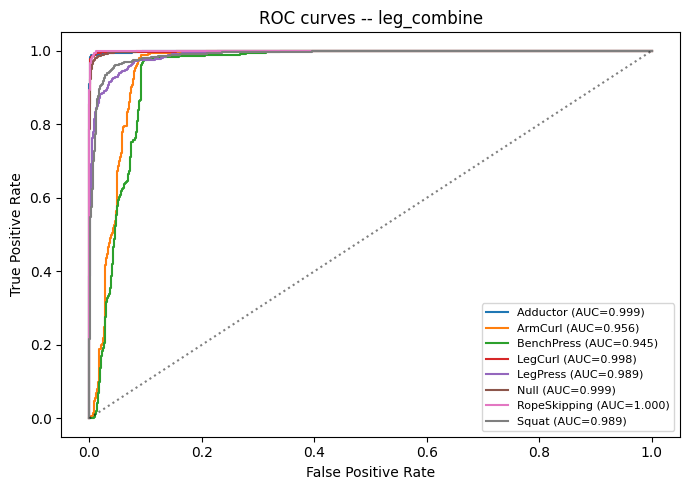

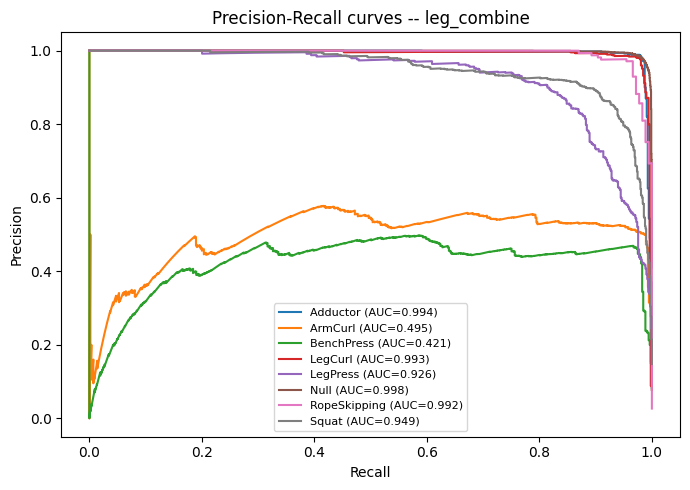

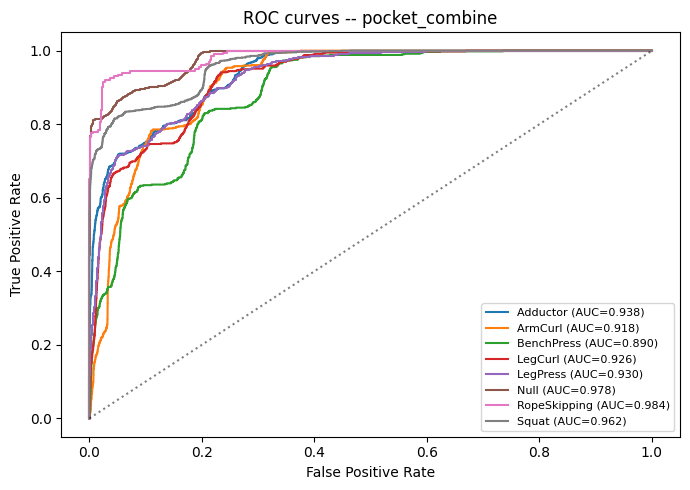

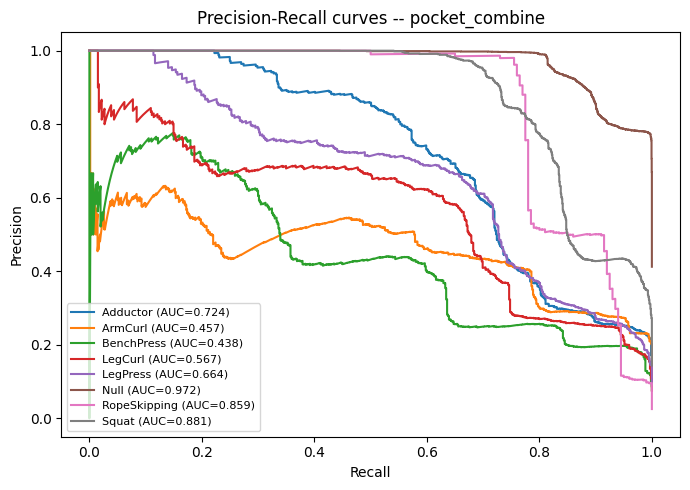

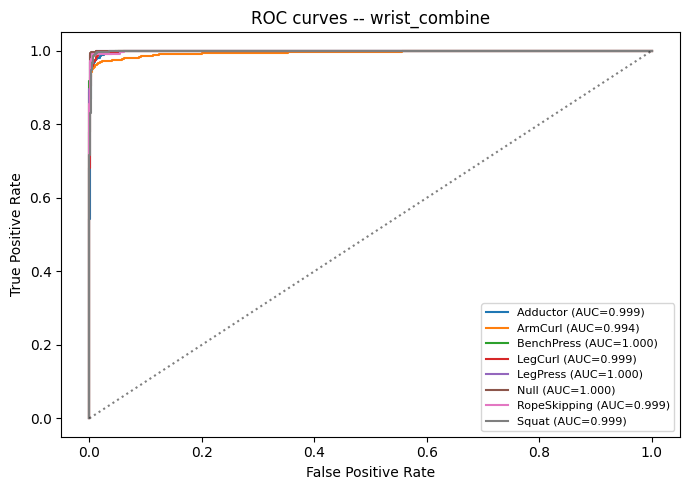

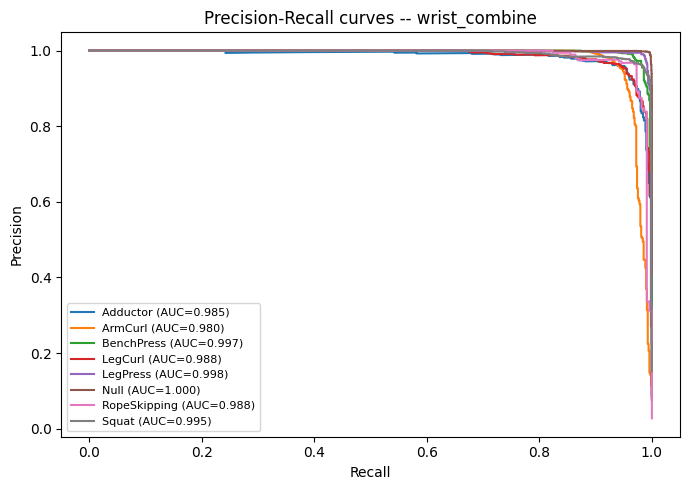

In [7]:
# --- ROC and Precision-Recall curves
for pos in positions:
    key = f"{pos}_combine"
    if key not in all_results or all_results[key].get("y_proba") is None or len(all_results[key]["y_proba"]) == 0:
        print(f"[{key}] No probabilities available yet -- re-run Section 5 to enable this plot.")
        continue

    y_true_k = np.array(all_results[key]["y_true"])
    y_proba_k = all_results[key]["y_proba"]
    n_cls = len(classes_labels)
    y_bin = label_binarize(y_true_k, classes=range(n_cls))

    # ROC curves
    plt.figure(figsize=(7, 5))
    for i in range(n_cls):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_proba_k[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{classes_labels[i]} (AUC={roc_auc:.3f})")
    plt.plot([0, 1], [0, 1], "k:", alpha=0.5)
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"ROC curves -- {key}"); plt.legend(fontsize=8); plt.tight_layout()
    plt.savefig(f"roc_curves_{key}.png", dpi=300, bbox_inches="tight")
    plt.show()

    # Precision-Recall curves
    plt.figure(figsize=(7, 5))
    for i in range(n_cls):
        prec, rec, _ = precision_recall_curve(y_bin[:, i], y_proba_k[:, i])
        pr_auc = auc(rec, prec)
        plt.plot(rec, prec, label=f"{classes_labels[i]} (AUC={pr_auc:.3f})")
    plt.xlabel("Recall"); plt.ylabel("Precision")
    plt.title(f"Precision-Recall curves -- {key}"); plt.legend(fontsize=8); plt.tight_layout()
    plt.savefig(f"pr_curves_{key}.png", dpi=300, bbox_inches="tight")
    plt.show()


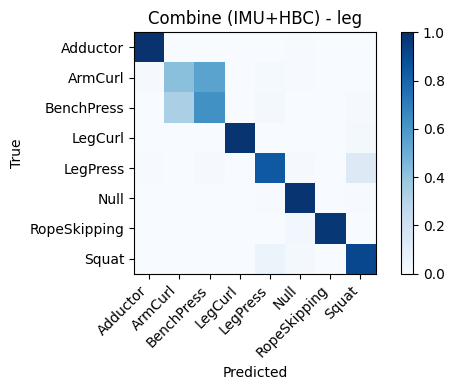

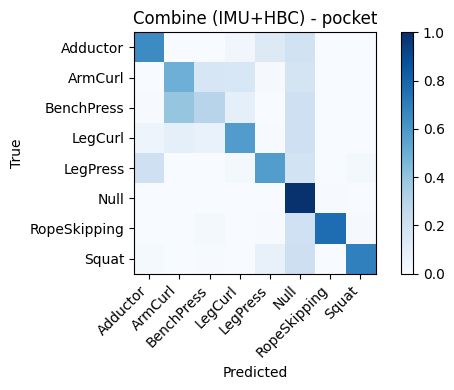

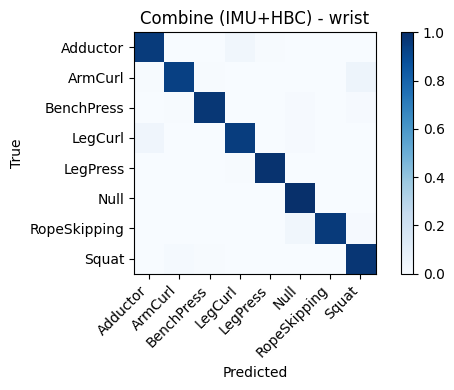

In [8]:

def plot_confusion(y_true, y_pred, classes, title):
    # Row-normalized confusion matrix (each row sums to 1), so each cell shows
    # the fraction of true-class samples predicted as each class.
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(classes))), normalize="true")
    fig, ax = plt.subplots(figsize=(6, 4))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=45, ha="right")
    ax.set_yticks(range(len(classes)))
    ax.set_yticklabels(classes)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    plt.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()


# Plot one confusion matrix per sensor position, using the "combine" (IMU+HBC)
# configuration, which is expected to give the best overall performance.
for pos in positions:
    key = f"{pos}_combine"
    if key in all_results and all_results[key]["y_true"]:
        plot_confusion(all_results[key]["y_true"], all_results[key]["y_pred"],
                       classes_labels, f"Combine (IMU+HBC) - {pos}")



## 7 . Repetition counting (Acc, Gyro, HBC)

Follows Sec. IV-D of the paper: smoothing via **FFT/IFFT** (low-pass filter)
and **peak detection** with `peakutils`, comparing the detected number of
repetitions with the real one.

**Important note**: the public dataset does not contain an explicit label for
the number of repetitions per segment. The paper states that machine/free-
weight exercises (Adductor, ArmCurl, BenchPress, LegCurl, LegPress,
RopeSkipping, Squat) were performed as **3x10 repetitions per session**; here
we therefore assume **30 repetitions per continuous segment** of those
classes as an approximate ground truth. Aerobic exercises (Riding, Running,
StairClimber, Walking) are excluded from this analysis because the "real"
number of cycles depends on cadence and cannot be derived from the protocol
described in the paper without further annotations.


In [10]:

# Exercises performed with machines/free weights, assumed to follow a fixed
# rep scheme (3 sets x 10 reps per session, per the paper's protocol)
ANAEROBIC_CLASSES = ["Adductor", "ArmCurl", "BenchPress", "LegCurl", "LegPress",
                      "RopeSkipping", "Squat"]
REPS_PER_SEGMENT = 30  # 3 sets x 10 reps; assumption based on the experimental protocol stated in the paper


def magnitude(df_seg, cols):
    # For a single column (e.g. just the HBC channel), return it as-is.
    # For multiple columns (e.g. the 3 accelerometer axes), return their
    # Euclidean norm (vector magnitude) at each time step.
    if len(cols) == 1:
        return df_seg[cols[0]].values
    return np.sqrt((df_seg[cols] ** 2).sum(axis=1)).values # length of a 3D vector (sqrt(A_x²+A_y²+A_z²))-> intensity indipendent by the movement direction


def fft_smooth(signal, fs=20, cutoff=2.5):
    # Low-pass filter: zero out all frequency components above `cutoff` Hz, then transform back to the time domain.
    # This removes high-frequency noise while preserving the slower repetition cycles.
    n = len(signal)
    if n < 4:                                             # min number of samples
        return signal
    freqs = np.fft.rfftfreq(n, d=1 / fs)                  # d : interval between two consecutive samples
    spec = np.fft.rfft(signal)                            # time to frequency domain -> output: array of frequencies
    spec[freqs > cutoff] = 0                              # denoising the signal
    return np.fft.irfft(spec, n=n)                        # frequency to time domain


def count_repetitions(signal, fs=20, cutoff=2.5, min_dist_sec=1.5, thres=0.3):
    # Smooth the raw signal, remove its DC offset (mean), then detect peaks
    # using peakutils. `thres` is a relative height threshold and `min_dist`
    # enforces a minimum spacing between consecutive peaks (in samples), to
    # avoid counting noisy sub-peaks as separate repetitions.
    smooth = fft_smooth(signal, fs=fs, cutoff=cutoff)
    smooth = smooth - smooth.mean()
    if smooth.max() == smooth.min():
        # Flat signal (e.g. all zeros): no peaks to detect
        return 0, smooth, np.array([])
    peaks = peakutils.indexes(smooth, thres=thres, min_dist=max(1, int(min_dist_sec * fs)))
    return len(peaks), smooth, peaks


def counting_accuracy(count_detected, count_real):
    # Accuracy metric used in the paper
    if count_real == 0:
        return np.nan
    return 1.0 - abs(count_detected - count_real) / count_real


def extract_segments(df_pos_subj, label_col="Workout"):
    # Extracts segments from an ordered time series.
    # Each segment is a (label, start_index, end_index) tuple corresponding to
    # one uninterrupted exercise set within a session.
    segments = []
    labels = df_pos_subj[label_col].values
    current_label = labels[0] if len(labels) else None
    start_idx = 0
    for i, lbl in enumerate(labels):
        if lbl != current_label:
            segments.append((current_label, start_idx, i)) # segment saved with end_index = i
            current_label = lbl
            start_idx = i
    if len(labels):
        # In order to close the final open segment
        segments.append((current_label, start_idx, len(labels)))
    return segments


In [13]:

counting_rows = []

# Iterate over every (position, subject) combination and extract continuous
# exercise segments, then run repetition counting on each of the three signal
# sources independently (Acc magnitude, Gyro magnitude, raw HBC channel).
for pos in positions:
    df_pos = df[df["Position"] == pos] if "Position" in df.columns else df
    for subj, g in df_pos.groupby("Subject"): # g : sub-dataframe which contains rows of a particular subj
        g = g.reset_index(drop=True)
        segments = extract_segments(g, label_col="Workout")

        for label, s, e in segments:
            # Only analyze anaerobic/machine exercises (known rep scheme) and
            # skip segments that are too short to contain a meaningful signal.
            if label not in ANAEROBIC_CLASSES or (e - s) < 20: # < 20 samples = 1 second with 20 Hz
                continue
            seg = g.iloc[s:e] # positional slicing -> it extracts the rows from the dataframe related to the interval [s:e]

            for source, cols in [("Acc", ["A_x", "A_y", "A_z"]),("Gyro", ["G_x", "G_y", "G_z"]), ("HBC", ["C_1"])]: # to perform comparison like Table IV/Fig.8 in the paper
                sig = magnitude(seg, cols) # 1D signal
                cutoff_hz = 5.0 if label == "RopeSkipping" else 2.5
                seg_duration_sec = (e - s) / 20
                min_dist_sec_adaptive = 0.6 * seg_duration_sec / REPS_PER_SEGMENT
                n_det, smooth, peaks = count_repetitions(sig, fs=20, cutoff=cutoff_hz,
                                           min_dist_sec=min_dist_sec_adaptive, thres=0.3)
                acc_c = counting_accuracy(n_det, REPS_PER_SEGMENT)
                counting_rows.append({"Position": pos, "Subject": subj, "Exercise": label,
                                       "Source": source, "Detected": n_det,
                                       "Accuracy": acc_c}) # every result accumulated as a dictionary

# Collect everything into a DataFrame and drop rows where accuracy could not be computed
counting_df = pd.DataFrame(counting_rows).dropna(subset=["Accuracy"])

# Average counting accuracy grouped by sensor position and signal source --
# this is the notebook's equivalent of Table IV in the paper.
counting_summary = counting_df.groupby(["Position", "Source"])["Accuracy"].agg(["mean", "std"]).round(3)
print(counting_summary)


                  mean    std
Position Source              
leg      Acc     0.888  0.092
         Gyro    0.871  0.154
         HBC     0.891  0.121
pocket   Acc     0.882  0.081
         Gyro    0.877  0.147
         HBC     0.876  0.161
wrist    Acc     0.891  0.075
         Gyro    0.859  0.171
         HBC     0.909  0.085


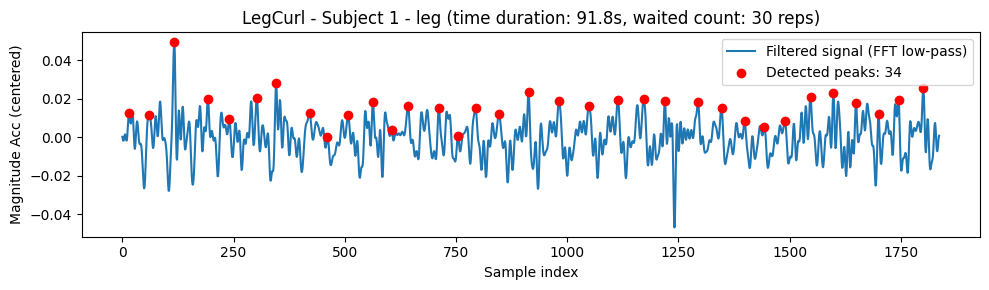

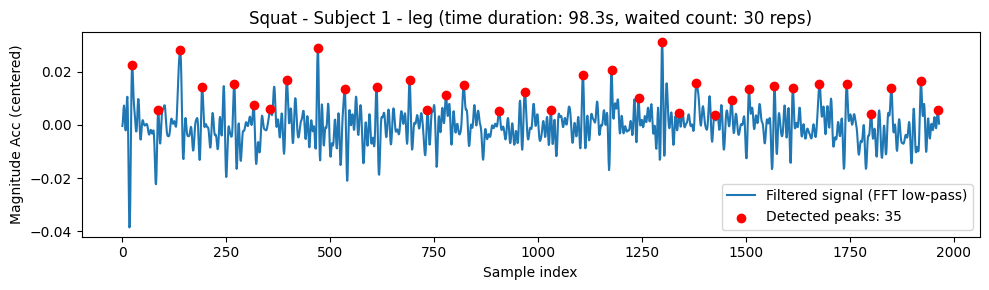

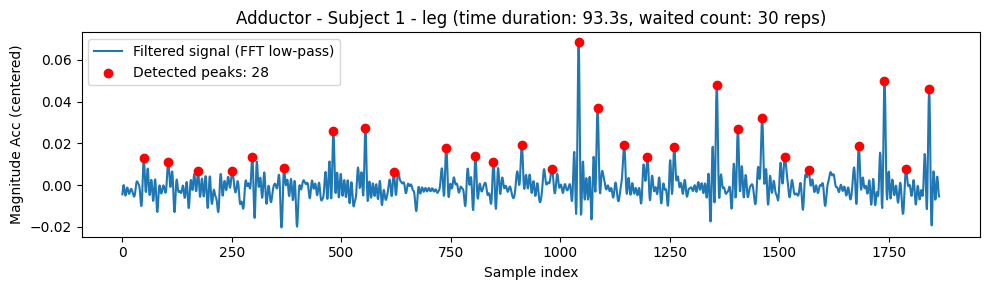

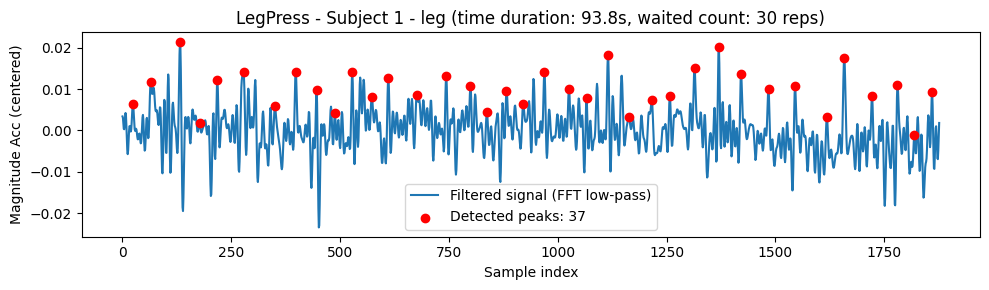

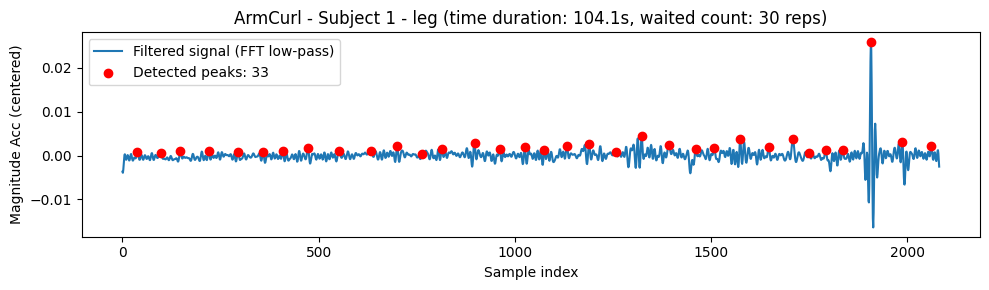

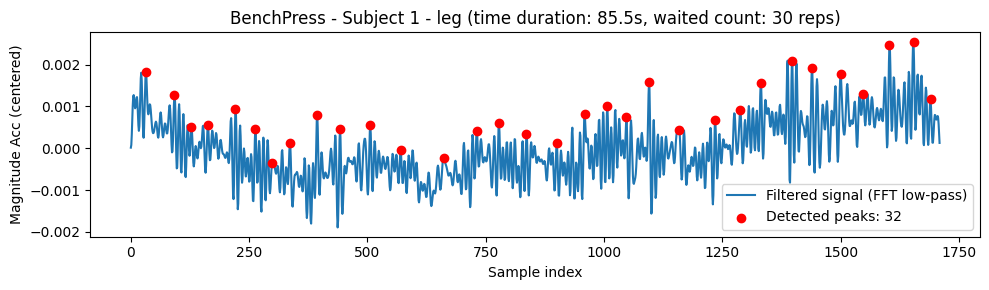

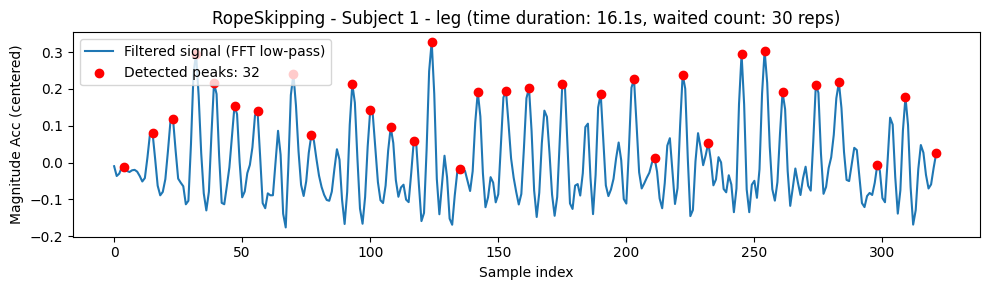

             Duration_sec        Detected       
                     mean median     mean median
Exercise                                        
Adductor            55.45  51.60    32.89   33.0
ArmCurl             60.00  60.25    33.82   34.0
BenchPress          50.18  52.00    33.29   33.0
LegCurl             48.70  46.60    32.55   33.0
LegPress            58.69  53.40    33.03   33.0
RopeSkipping        17.46  17.50    31.84   32.0
Squat               38.47  36.95    30.00   31.0


In [14]:
# --- DIAGNOSTIC: REAL SEGMENT LENGHT, PEAKS DETECTED
diag_rows = []
plotted_exercises = set()

for pos in positions:
    df_pos = df[df["Position"] == pos] if "Position" in df.columns else df
    for subj, g in df_pos.groupby("Subject"):
        g = g.reset_index(drop=True)
        segments = extract_segments(g, label_col="Workout")
        for label, s, e in segments:
            if label not in ANAEROBIC_CLASSES or (e - s) < 20:
                continue

            seg = g.iloc[s:e]
            sig = magnitude(seg, ["A_x", "A_y", "A_z"])
            cutoff_hz = 5.0 if label == "RopeSkipping" else 2.5
            seg_duration_sec = (e - s) / 20
            min_dist_sec_adaptive = 0.6 * seg_duration_sec / REPS_PER_SEGMENT
            n_det, smooth, peaks = count_repetitions(sig, fs=20, cutoff=cutoff_hz,
                                           min_dist_sec=min_dist_sec_adaptive, thres=0.3)

            diag_rows.append({"Exercise": label, "Duration_sec": (e - s) / 20, "Detected": n_det})

            # One graph per exercise
            if label not in plotted_exercises:
                fig, ax = plt.subplots(figsize=(10, 3))
                ax.plot(smooth, label="Filtered signal (FFT low-pass)")
                ax.scatter(peaks, smooth[peaks], color="red", zorder=5,
                           label=f"Detected peaks: {n_det}")
                ax.set_title(f"{label} - Subject {subj} - {pos} "
                             f"(time duration: {(e-s)/20:.1f}s, waited count: {REPS_PER_SEGMENT} reps)")
                ax.set_xlabel("Sample index")
                ax.set_ylabel("Magnitude Acc (centered)")
                ax.legend()
                plt.tight_layout()
                plt.show()
                plotted_exercises.add(label)

diag_df = pd.DataFrame(diag_rows)
print(diag_df.groupby("Exercise")[["Duration_sec", "Detected"]].agg(["mean", "median"]).round(2))

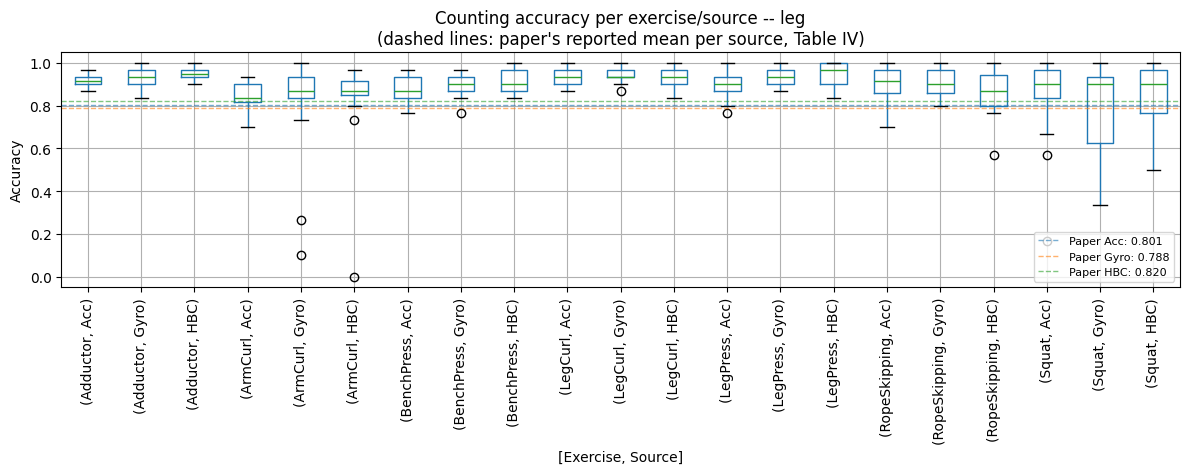

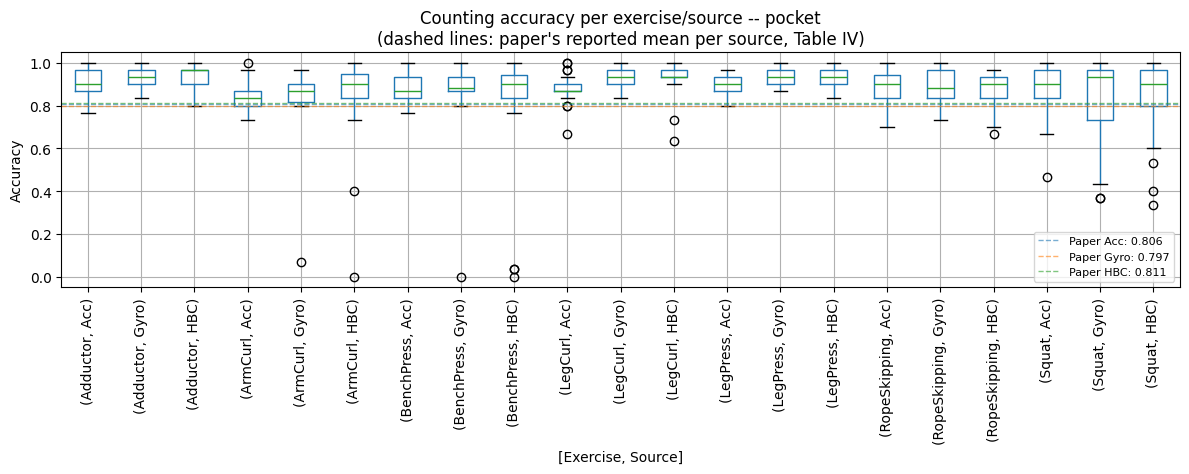

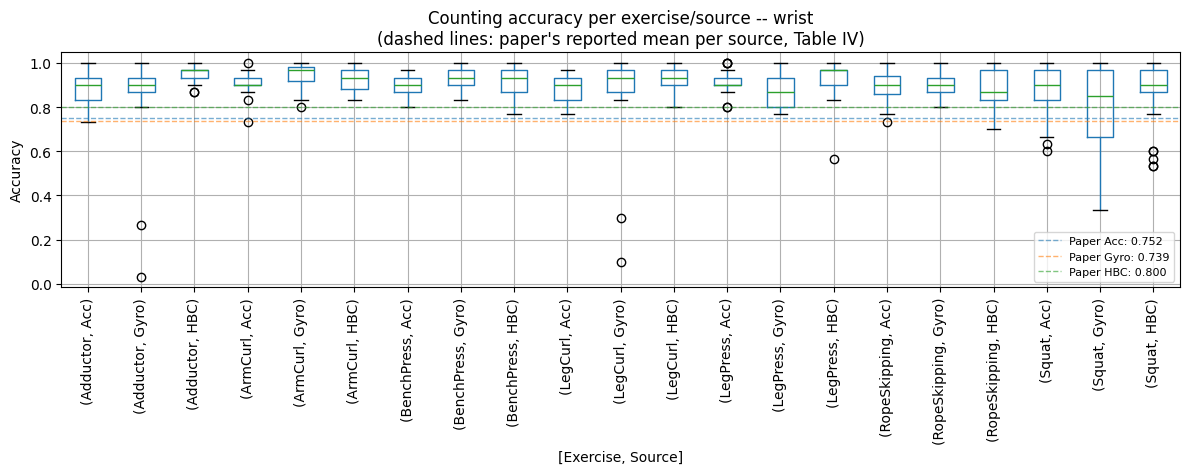

FINAL COUNTING SUMMARY vs. PAPER (Table IV)

--- leg ---
  Acc    ours=0.888 (std=0.092)  paper=0.801  diff=+0.087
  Gyro   ours=0.871 (std=0.154)  paper=0.788  diff=+0.083
  HBC    ours=0.891 (std=0.121)  paper=0.820  diff=+0.071

--- pocket ---
  Acc    ours=0.882 (std=0.081)  paper=0.806  diff=+0.076
  Gyro   ours=0.877 (std=0.147)  paper=0.797  diff=+0.080
  HBC    ours=0.876 (std=0.161)  paper=0.811  diff=+0.065

--- wrist ---
  Acc    ours=0.891 (std=0.075)  paper=0.752  diff=+0.139
  Gyro   ours=0.859 (std=0.171)  paper=0.739  diff=+0.120
  HBC    ours=0.909 (std=0.085)  paper=0.800  diff=+0.109


In [15]:
# --- Reference values from the paper (Table IV) for visual benchmarking ---
PAPER_COUNTING_REFERENCE = {
    "pocket": {"Acc": 0.806, "Gyro": 0.797, "HBC": 0.811},
    "leg":    {"Acc": 0.801, "Gyro": 0.788, "HBC": 0.820},
    "wrist":  {"Acc": 0.752, "Gyro": 0.739, "HBC": 0.800},
}

source_order = ["Acc", "Gyro", "HBC"]

for pos in positions:
    sub = counting_df[counting_df["Position"] == pos]
    if sub.empty:
        continue

    # Ensure a consistent Exercise/Source ordering on the x-axis across plots
    sub = sub.copy()
    sub["Source"] = pd.Categorical(sub["Source"], categories=source_order, ordered=True)

    fig, ax = plt.subplots(figsize=(12, 5))
    sub.boxplot(column="Accuracy", by=["Exercise", "Source"], ax=ax, rot=90)

    # Overlay the paper's reported mean accuracy for this position, one
    # horizontal dashed line per source, for direct visual comparison.
    if pos in PAPER_COUNTING_REFERENCE:
        colors = {"Acc": "tab:blue", "Gyro": "tab:orange", "HBC": "tab:green"}
        for source, ref_value in PAPER_COUNTING_REFERENCE[pos].items():
            ax.axhline(ref_value, linestyle="--", linewidth=1, alpha=0.6,
                       color=colors.get(source, "gray"),
                       label=f"Paper {source}: {ref_value:.3f}")
        ax.legend(fontsize=8, loc="lower right")

    ax.set_title(f"Counting accuracy per exercise/source -- {pos}\n"
                 f"(dashed lines: paper's reported mean per source, Table IV)")
    plt.suptitle("")
    plt.ylabel("Accuracy")
    plt.tight_layout()
    plt.savefig(f"counting_boxplot_{pos}.png", dpi=300, bbox_inches="tight")
    plt.show()

# --- Final summary table, saved for the report ----------------------------
print("=" * 70)
print("FINAL COUNTING SUMMARY vs. PAPER (Table IV)")
print("=" * 70)
for pos in positions:
    if pos not in PAPER_COUNTING_REFERENCE:
        continue
    print(f"\n--- {pos} ---")
    for source in source_order:
        row = counting_summary.loc[(pos, source)] if (pos, source) in counting_summary.index else None
        if row is not None:
            paper_val = PAPER_COUNTING_REFERENCE[pos][source]
            print(f"  {source:5s}  ours={row['mean']:.3f} (std={row['std']:.3f})  "
                  f"paper={paper_val:.3f}  diff={row['mean']-paper_val:+.3f}")

## 8 . Final summary

In [16]:

# Overview of all the results computed
print("=" * 70)
print("CLASSIFICATION SUMMARY -- Mean accuracy (LOSO)")
print("=" * 70)
print(pivot_acc.round(4))

print("\n" + "=" * 70)
print("CLASSIFICATION SUMMARY -- Mean macro F1 (LOSO)")
print("=" * 70)
print(pivot_f1.round(4))

print("\n" + "=" * 70)
print("COUNTING SUMMARY -- Mean accuracy per source and position")
print("=" * 70)
print(counting_summary)


CLASSIFICATION SUMMARY -- Mean accuracy (LOSO)
Position     leg  pocket   wrist
Sensor                          
cap       0.7329  0.6228  0.7076
combine   0.8808  0.7414  0.9765
imu       0.7793  0.8098  0.9681

CLASSIFICATION SUMMARY -- Mean macro F1 (LOSO)
Position     leg  pocket   wrist
Sensor                          
cap       0.6330  0.3996  0.6149
combine   0.7964  0.5904  0.9671
imu       0.6562  0.6912  0.9519

COUNTING SUMMARY -- Mean accuracy per source and position
                  mean    std
Position Source              
leg      Acc     0.888  0.092
         Gyro    0.871  0.154
         HBC     0.891  0.121
pocket   Acc     0.882  0.081
         Gyro    0.877  0.147
         HBC     0.876  0.161
wrist    Acc     0.891  0.075
         Gyro    0.859  0.171
         HBC     0.909  0.085



## Final notes about the code and differences with what is in the paper

- **FAST_MODE (Section 1.3)**: when enabled, this reduces training time by
  sampling fewer subjects, dropping some workout classes, downsampling the
  dominant `Null` class, restricting the (position, sensor_mode) grid, using
  a larger window stride, and enabling mixed precision.
- **Reduced epochs**: `epochs=150`, `patience=20` (or the smaller `FAST_MODE`
  values) instead of `epochs=1000`, `patience=100` from the original paper,
  for faster iteration.
- **Framework port, not a literal translation**: this notebook reimplements
  the *conceptual* architecture described in the paper (CNN block, multi-head
  self-attention, dilated convolution, sliding-window ensembling), not a
  weight-for-weight, layer-for-layer clone of the authors' Keras code.
- **Repetition counting**: the ground truth (3x10 repetitions/segment) is
  **assumed** from the experimental protocol described in the paper, not from
  an explicit label in the public dataset. Aerobic exercises
  (Running, Walking, Riding, StairClimber) are excluded.
- **User authentication** (Sec. IV-E of the paper, ~92-95% accuracy on
  Running) is not implemented here, but can be obtained by reusing the same
  `ConvBlock` followed by a linear classifier, replacing the `Workout` label
  with the `Subject` label and filtering only on the Running exercise.
- **Paper vs. code discrepancy (average pooling)**: the paper's text (Sec. IV-B) states that average pooling is applied after the second and third CNN layers, but the actual Conv_block_ function in the authors' published code never calls AveragePooling2D (despite importing it), even though the accompanying dropout layers are present exactly as described. This PyTorch port follows the authors' actual code behavior (no pooling) rather than the paper's prose description.
